# Positional Embedding

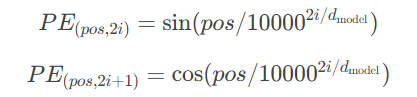

In [ ]:
import torch.nn as nn
import torch

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model, dropout=0.1):
        super().__init__()

        self.dropout = nn.Dropout(dropout)

        #criando matriz das posições
        pos_matrix = (torch.arange(
            0, max_len # [L]
        ).unsqueeze(1)) #[L, D]

        #criando matriz pe
        pe = torch.zeros(
                    max_len,
                    d_model
                ) # [L, D]
 
        #termo de divisão
        div_term = (
            10000.0 ** (
                torch.arange(0, d_model, 2) # 2i 
                /d_model
            )
        )

        #aplicando seno aos pares
        pe[:, 0::2] = torch.sin(pos_matrix / div_term)

        #aplicando cosseno nos ímpares
        pe[:, 1::2] = torch.cos(pos_matrix / div_term)

        #para deixar no padrão esperado pelo embedding de [B, L, D]
        pe = pe.unsqueeze(0)

        #levar self.pe para buffer, pois ele não será  treinado. 
        self.register_buffer("pe", pe)

    def forward(self, x): # esse x represneta a matriz de embeddings
        L = x.shape[1]
        return self.dropout(x + self.pe[:,:L,:])


- PE é sinusoidal e fixo.
- Shape: [1, max_len, d_model].
- Dimensões pares usam seno.
- Dimensões ímpares usam cosseno.
- É somado aos embeddings.

---

obs: Existem 3 tipos de tensores:
- Tensor Comum: não é parametro do modelo
- nn.Parameter: parametro treinamento
- register_buffer: tensor persistente no modulo, mas não treinavel